In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/train_u6lujuX_CVtuZ9i.csv")

Mounted at /content/drive


In [2]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df.shape

(614, 13)

In [4]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [5]:
df.dtypes

,0
Loan_ID,object
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


In [6]:
df['Loan_Status'].value_counts()

,count
Loan_Status,
Y,422
N,192


In [7]:
df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [8]:
print("Duplicates",df.duplicated().sum())

#df=df.drop('Loan_ID',axis=1)

df['Dependents']=df['Dependents'].replace('3+','3')

for col in ['Gender','Married','Dependents','Self_Employed']:
  df[col]=df[col].fillna(df[col].mode()[0])


df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Loan_Amount_Term']=df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])
df['Credit_History']=df['Credit_History'].fillna(df['Credit_History'].median())

df['Dependents']=df['Dependents'].astype(int)

print(df.isnull().sum())
df.info()

Duplicates 0
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             614 non-null    object 
 2   Married            614 non-null    object 
 3   Dependents         614 non-null    int64  
 4   Education          614 non-null    object 
 5   Self_Employed      614 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    fl

In [9]:
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['Married'] = df['Married'].map({'Yes': 1, 'No': 0})
df['Education'] = df['Education'].map({'Graduate': 1, 'Not Graduate': 0})
df['Self_Employed'] = df['Self_Employed'].map({'Yes': 1, 'No': 0})
df = pd.get_dummies(df, columns=['Property_Area'], drop_first=True, dtype=int)
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
0,LP001002,1,0,0,1,0,5849,0.0,128.0,360.0,1.0,1,0,1
1,LP001003,1,1,1,1,0,4583,1508.0,128.0,360.0,1.0,0,0,0
2,LP001005,1,1,0,1,1,3000,0.0,66.0,360.0,1.0,1,0,1
3,LP001006,1,1,0,0,0,2583,2358.0,120.0,360.0,1.0,1,0,1
4,LP001008,1,0,0,1,0,6000,0.0,141.0,360.0,1.0,1,0,1


In [10]:
print(df.shape)
print(df.isnull().sum().sum(), "missing values left")
print(df.head())

(614, 14)
0 missing values left
    Loan_ID  Gender  Married  Dependents  Education  Self_Employed  \
0  LP001002       1        0           0          1              0   
1  LP001003       1        1           1          1              0   
2  LP001005       1        1           0          1              1   
3  LP001006       1        1           0          0              0   
4  LP001008       1        0           0          1              0   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0       128.0             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History  Loan_Status  Property_Area_Semiurban  Property_Area_Urban  
0             1.0            1           

Loan_Status
1    68.729642
0    31.270358
Name: proportion, dtype: float64


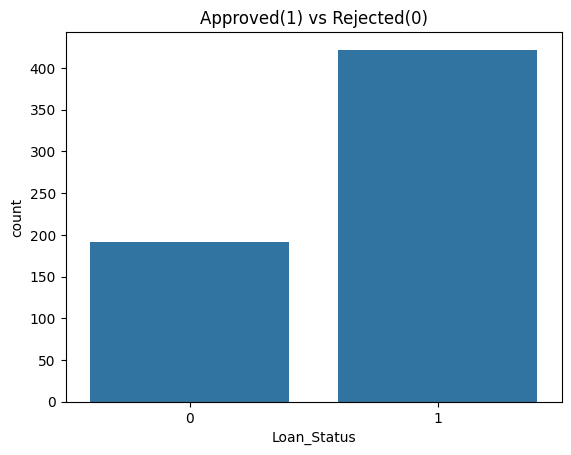

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df['Loan_Status'].value_counts(normalize=True)*100)
sns.countplot(x='Loan_Status',data=df)
plt.title("Approved(1) vs Rejected(0)")
plt.show()

Credit_History
0.0     7.865169
1.0    79.047619
Name: Loan_Status, dtype: float64


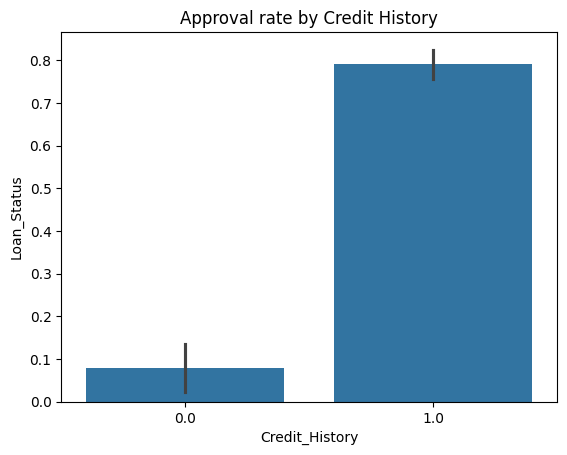

In [12]:
print(df.groupby('Credit_History')['Loan_Status'].mean() * 100)
sns.barplot(x='Credit_History', y='Loan_Status', data=df)
plt.title("Approval rate by Credit History")
plt.show()

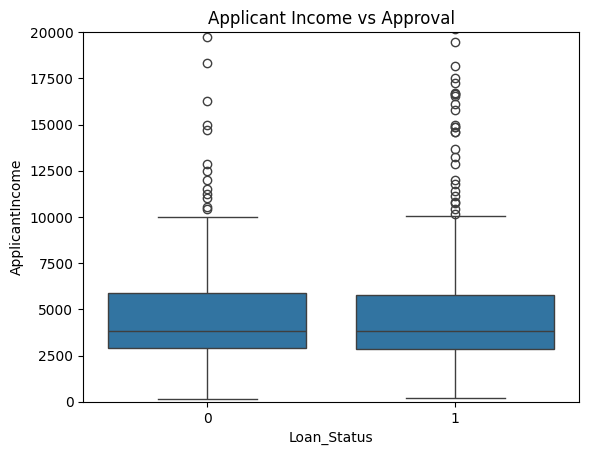

In [13]:
sns.boxplot(x='Loan_Status', y='ApplicantIncome', data=df)
plt.ylim(0, 20000)
plt.title("Applicant Income vs Approval")
plt.show()

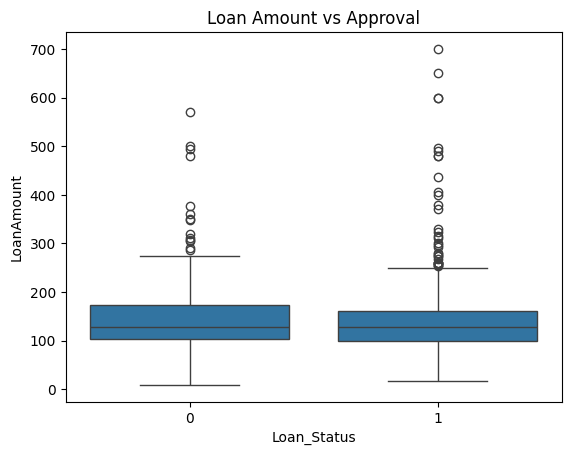

In [14]:
sns.boxplot(x='Loan_Status', y='LoanAmount', data=df)
plt.title("Loan Amount vs Approval")
plt.show()

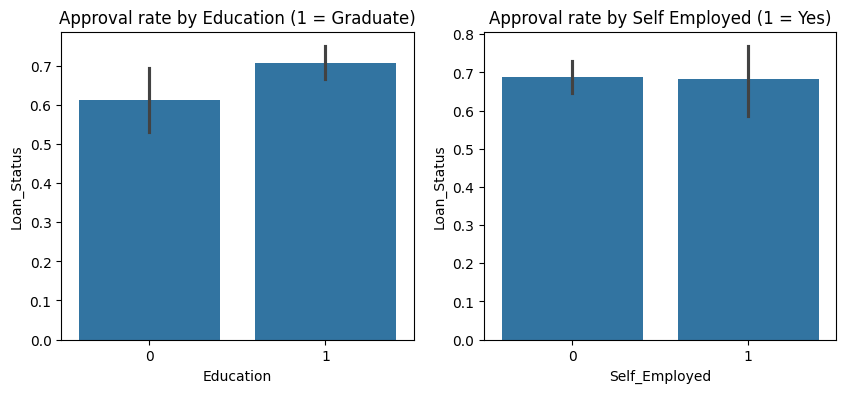

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(x='Education', y='Loan_Status', data=df, ax=ax[0])
ax[0].set_title("Approval rate by Education (1 = Graduate)")
sns.barplot(x='Self_Employed', y='Loan_Status', data=df, ax=ax[1])
ax[1].set_title("Approval rate by Self Employed (1 = Yes)")
plt.show()

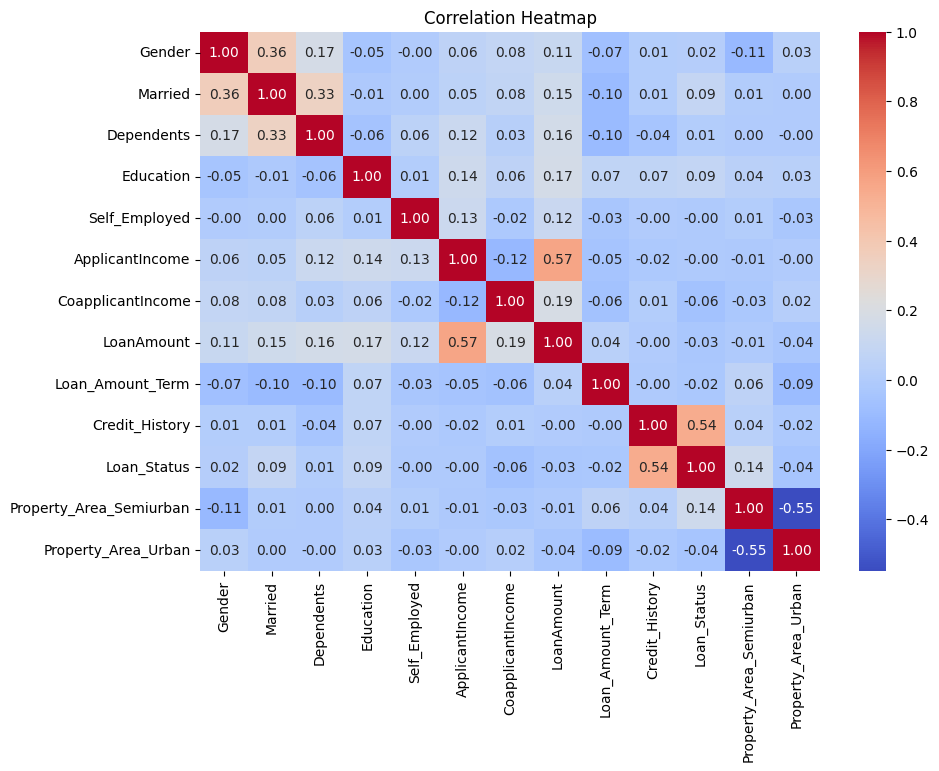

Loan_Status                1.000000
Credit_History             0.540556
Property_Area_Semiurban    0.136540
Married                    0.091478
Education                  0.085884
Gender                     0.017987
Dependents                 0.010118
Self_Employed             -0.003700
ApplicantIncome           -0.004710
Loan_Amount_Term          -0.022549
LoanAmount                -0.033214
Property_Area_Urban       -0.043621
CoapplicantIncome         -0.059187
Name: Loan_Status, dtype: float64


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/train_u6lujuX_CVtuZ9i.csv")

df = df.drop('Loan_ID', axis=1)
df['Dependents'] = df['Dependents'].replace('3+', '3')

for col in ['Gender', 'Married', 'Dependents', 'Self_Employed']:
    df[col] = df[col].fillna(df[col].mode()[0])

df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])
df['Dependents'] = df['Dependents'].astype(int)

df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['Married'] = df['Married'].map({'Yes': 1, 'No': 0})
df['Education'] = df['Education'].map({'Graduate': 1, 'Not Graduate': 0})
df['Self_Employed'] = df['Self_Employed'].map({'Yes': 1, 'No': 0})
df = pd.get_dummies(df, columns=['Property_Area'], drop_first=True, dtype=int)

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

print(df.corr()['Loan_Status'].sort_values(ascending=False))

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = df.drop('Loan_Status', axis=1)
y = df['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("First 10 predictions:", y_pred[:10])
print("First 10 probabilities:", y_prob[:10].round(3))

Train shape: (491, 12) Test shape: (123, 12)
First 10 predictions: [0 1 1 1 1 1 1 1 1 1]
First 10 probabilities: [0.085 0.875 0.736 0.78  0.867 0.806 0.878 0.849 0.696 0.729]


Accuracy : 0.862
Precision: 0.84
Recall   : 0.988
F1-score : 0.908
ROC-AUC  : 0.848

Classification Report:

              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



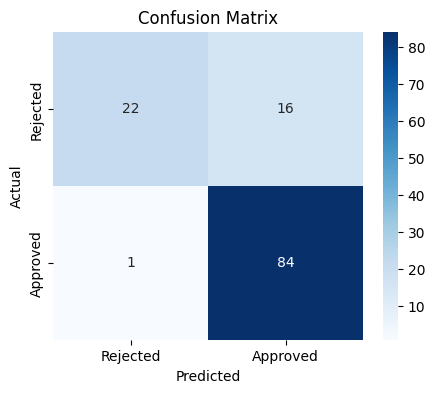

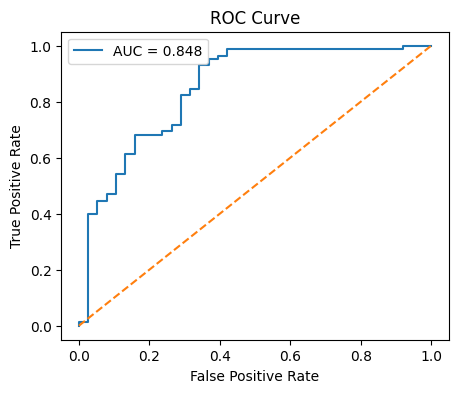

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rejected', 'Approved'],
            yticklabels=['Rejected', 'Approved'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [22]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display

def predict_loan(gender, married, dependents, education, self_emp,
                 app_income, co_income, loan_amount, term, credit, area):
    row = {
        'Gender': 1 if gender == 'Male' else 0,
        'Married': 1 if married == 'Yes' else 0,
        'Dependents': dependents,
        'Education': 1 if education == 'Graduate' else 0,
        'Self_Employed': 1 if self_emp == 'Yes' else 0,
        'ApplicantIncome': app_income,
        'CoapplicantIncome': co_income,
        'LoanAmount': loan_amount,
        'Loan_Amount_Term': term,
        'Credit_History': credit,
        'Property_Area_Semiurban': 1 if area == 'Semiurban' else 0,
        'Property_Area_Urban': 1 if area == 'Urban' else 0
    }
    data = pd.DataFrame([row])[X.columns].astype(float)
    data[num_cols] = scaler.transform(data[num_cols])
    prob = model.predict_proba(data)[0][1]
    pred = 1 if prob >= 0.5 else 0
    return prob, pred

# Input widgets
gender = widgets.Dropdown(options=['Male', 'Female'], description='Gender:')
married = widgets.Dropdown(options=['Yes', 'No'], description='Married:')
dependents = widgets.Dropdown(options=[0, 1, 2, 3], description='Dependents:')
education = widgets.Dropdown(options=['Graduate', 'Not Graduate'], description='Education:')
self_emp = widgets.Dropdown(options=['No', 'Yes'], description='Self Emp:')
app_income = widgets.IntText(value=5000, description='App Income:')
co_income = widgets.IntText(value=0, description='Co Income:')
loan_amount = widgets.IntText(value=130, description='Loan (000s):')
term = widgets.Dropdown(options=[360, 180, 480, 300, 240, 120, 84, 60, 36, 12],
                        description='Term (months):')
credit = widgets.Dropdown(options=[1, 0], description='Credit Hist:')
area = widgets.Dropdown(options=['Urban', 'Semiurban', 'Rural'], description='Area:')
button = widgets.Button(description='Predict', button_style='primary')
output = widgets.Output()

def on_click(b):
    with output:
        output.clear_output()
        prob, pred = predict_loan(gender.value, married.value, dependents.value,
                                  education.value, self_emp.value, app_income.value,
                                  co_income.value, loan_amount.value, term.value,
                                  credit.value, area.value)
        print(f"Approval probability: {prob*100:.1f}%")
        print("Prediction:", "APPROVED" if pred == 1 else "REJECTED")

button.on_click(on_click)

print("Loanlytics: Loan Approval Prediction")
display(gender, married, dependents, education, self_emp, app_income,
        co_income, loan_amount, term, credit, area, button, output)

Loanlytics: Loan Approval Prediction


Dropdown(description='Gender:', options=('Male', 'Female'), value='Male')

Dropdown(description='Married:', options=('Yes', 'No'), value='Yes')

Dropdown(description='Dependents:', options=(0, 1, 2, 3), value=0)

Dropdown(description='Education:', options=('Graduate', 'Not Graduate'), value='Graduate')

...

Dropdown(description='Term (months):', options=(360, 180, 480, 300, 240, 120, 84, 60, 36, 12), value=360)

Dropdown(description='Credit Hist:', options=(1, 0), value=1)

Dropdown(description='Area:', options=('Urban', 'Semiurban', 'Rural'), value='Urban')

Button(button_style='primary', description='Predict', style=ButtonStyle())

Output()

In [23]:
cases = [
    ("Strong applicant", ['Male','Yes',0,'Graduate','No',8000,2000,120,360,1,'Semiurban']),
    ("Bad credit history", ['Male','Yes',1,'Graduate','No',6000,1500,150,360,0,'Urban']),
    ("Low income, high loan", ['Female','No',0,'Not Graduate','Yes',2000,0,250,360,1,'Rural']),
    ("Average applicant", ['Female','Yes',2,'Graduate','No',4500,1000,130,360,1,'Urban']),
    ("Bad credit, high income", ['Male','Yes',2,'Graduate','Yes',15000,5000,200,360,0,'Semiurban']),
]

rows = []
for name, c in cases:
    prob, pred = predict_loan(*c)
    rows.append({'Case': name, 'Credit_History': c[9], 'Income': c[5],
                 'Loan': c[7], 'Probability %': round(prob*100, 1),
                 'Prediction': 'Approved' if pred == 1 else 'Rejected'})

print(pd.DataFrame(rows).to_string(index=False))

                   Case  Credit_History  Income  Loan  Probability % Prediction
       Strong applicant               1    8000   120           86.3   Approved
     Bad credit history               0    6000   150           14.5   Rejected
  Low income, high loan               1    2000   250           57.0   Approved
      Average applicant               1    4500   130           83.8   Approved
Bad credit, high income               0   15000   200           18.4   Rejected


In [24]:
import joblib, sklearn
from google.colab import files

joblib.dump(model, 'model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'columns.pkl')

print("scikit-learn version:", sklearn.__version__)

files.download('model.pkl')
files.download('scaler.pkl')
files.download('columns.pkl')

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>